In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

## coin toss (last time, I swear)

In [7]:
def coin_posteriors(n_flips, true_p=0.5):

    flips = np.random.binomial(1, true_p, size=n_flips)

    results = [(0, 1, 1)]  # Uniform prior: Beta(1, 1)

    heads = 0

    for n, flip in enumerate(flips, start=1):

        heads = heads + flip

        tails = n - heads

        # Uniform prior + observed heads and tails

        alpha_post = 1 + heads

        beta_post = 1 + tails

        results.append((n, alpha_post, beta_post))

    return results

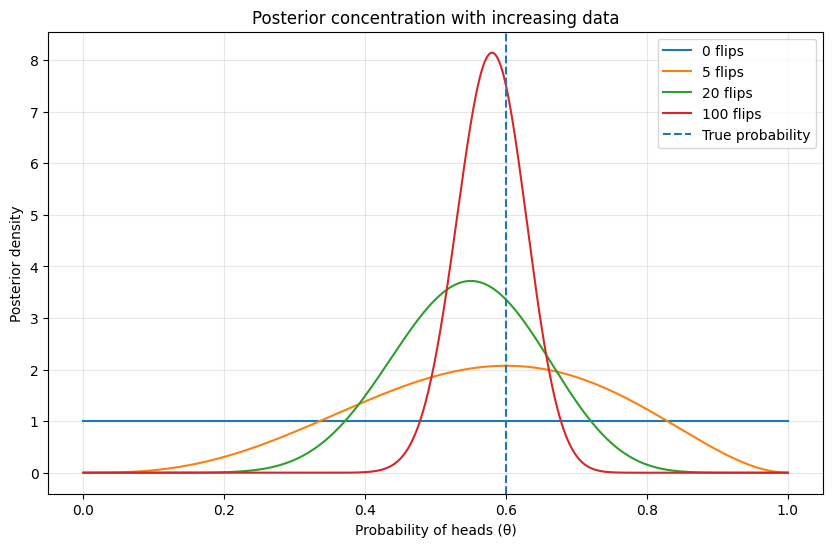

In [22]:
p_h_true = 0.6
results = coin_posteriors(n_flips=100, true_p=p_h_true)

checkpoints = [0, 5, 20, 100]

theta = np.linspace(0, 1, 1000)

plt.figure(figsize=(10, 6))

for n, alpha_post, beta_post in results:

    if n in checkpoints:

        plt.plot(

            theta,

            stats.beta.pdf(theta, alpha_post, beta_post),

            label=f"{n} flips"

        )

plt.axvline(p_h_true, linestyle="--", label="True probability")

plt.xlabel("Probability of heads (θ)")

plt.ylabel("Posterior density")

plt.title("Posterior concentration with increasing data")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))

line, = ax.plot([], [], lw=2, label="Posterior")

ax.axvline(p_h_true, color="red", linestyle="--",

           label=f"True p = {p_h_true}")

ax.set_xlim(0, 1)

ax.set_xlabel("Probability of heads")

ax.set_ylabel("Posterior density")

ax.legend()

def update(frame):

    n, alpha_post, beta_post = results[frame]

    posterior = stats.beta.pdf(theta, alpha_post, beta_post)

    line.set_data(theta, posterior)

    # Adjust y-axis as posterior sharpens

    ax.set_ylim(0, max(2, posterior.max() * 1.1))

    ax.set_title(f"Bayesian inference after {n} coin flips")

    return line,

ani = FuncAnimation(

    fig,

    update,

    frames=len(results),

    interval=50,       # milliseconds between frames

    repeat=False

)



plt.close(fig)
display(HTML(ani.to_jshtml()))

## lighthouse locator

In [35]:
def lighthouse_observations(n_flashes, alpha_true=10, beta_true=2):

    """

    Simulate flash detection positions along a coastline.

    alpha_true: lighthouse position along the coast

    beta_true: lighthouse distance from the coast

    """

    x = alpha_true + beta_true * np.random.standard_cauchy(n_flashes)

    return x

alpha_true = 10

beta_true = 4

x = lighthouse_observations(

    n_flashes=100,

    alpha_true=alpha_true,

    beta_true=beta_true

)

In [36]:
def lighthouse_posteriors(x, beta_known=2, alpha_grid=None):

    """

    Return the posterior density for alpha after each observation.

    Assumes known beta and a uniform prior over alpha_grid.

    """

    if alpha_grid is None:

        # Broad enough for this illustrative simulation

        alpha_grid = np.linspace(-50, 70, 1500)

    log_likelihood = np.zeros(len(alpha_grid))

    results = []

    # Uniform prior on the grid: posterior initially uniform

    posterior = np.ones(len(alpha_grid))

    posterior /= np.trapz(posterior, alpha_grid)

    results.append((0, posterior.copy()))

    for n, xi in enumerate(x, start=1):

        # Add the log-likelihood contribution of this observation

        log_likelihood += (

            -np.log((xi - alpha_grid)**2 + beta_known**2)

        )

        # Stabilize exponentiation to avoid numerical underflow

        log_post = log_likelihood - np.max(log_likelihood)

        posterior = np.exp(log_post)

        posterior /= np.trapz(posterior, alpha_grid)

        results.append((n, posterior.copy()))

    return alpha_grid, results

alpha_grid, results = lighthouse_posteriors(

    x, beta_known=beta_true

)



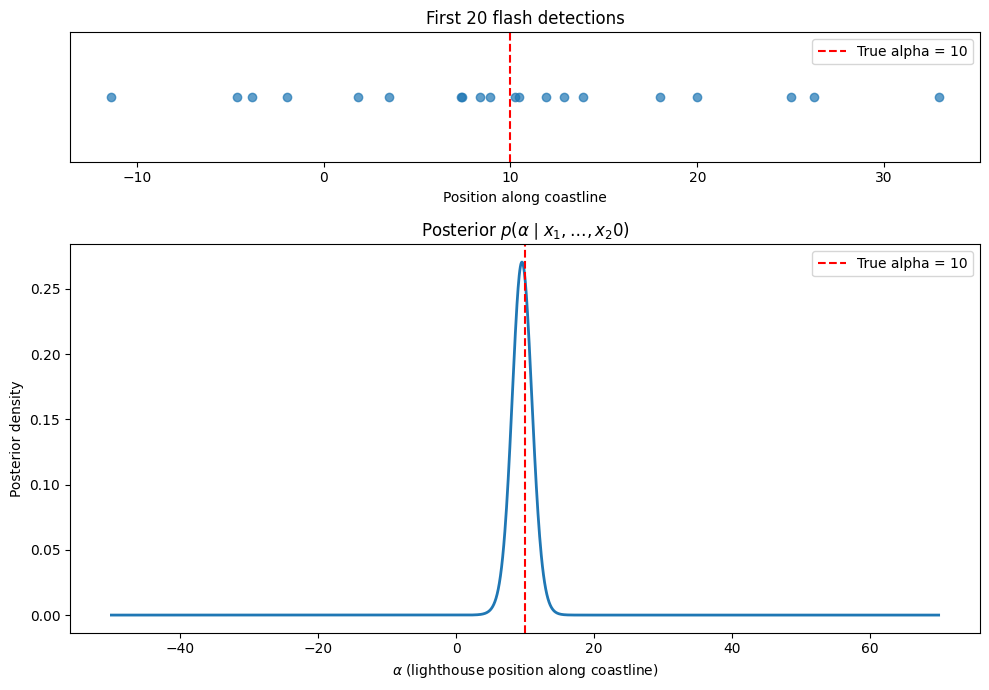

In [37]:
n = 20  # Number of flashes to display

fig, (ax1, ax2) = plt.subplots(

    2, 1, figsize=(10, 7), gridspec_kw={"height_ratios": [1, 3]}

)

# Top: observed flash positions along the coastline

ax1.scatter(x[:n], np.zeros(n), alpha=0.7)

ax1.axvline(alpha_true, color="red", linestyle="--",

            label=f"True alpha = {alpha_true}")

ax1.set_xlabel("Position along coastline")

ax1.set_yticks([])

ax1.set_title(f"First {n} flash detections")

ax1.legend()

# Bottom: posterior distribution for alpha

_, posterior = results[n]

ax2.plot(alpha_grid, posterior, linewidth=2)

ax2.axvline(alpha_true, color="red", linestyle="--",

            label=f"True alpha = {alpha_true}")

ax2.set_xlabel(r"$\alpha$ (lighthouse position along coastline)")

ax2.set_ylabel("Posterior density")

ax2.set_title(rf"Posterior $p(\alpha \mid x_1,\ldots,x_{n})$")

ax2.legend()

plt.tight_layout()

plt.show()

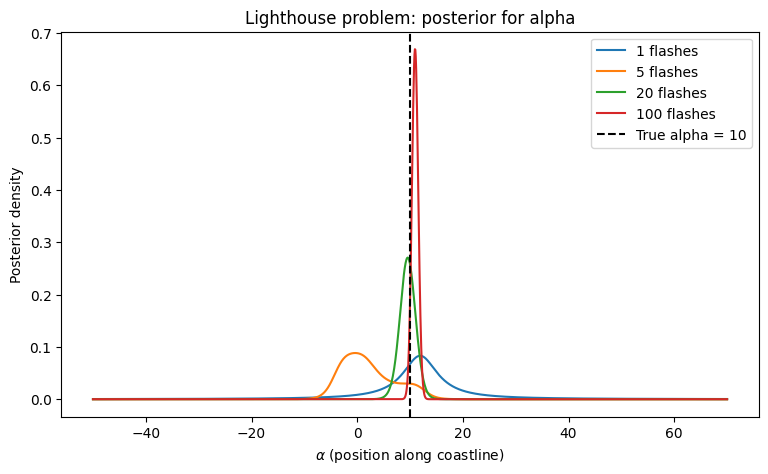

In [38]:
fig, ax = plt.subplots(figsize=(9, 5))

for n in [1, 5, 20, 100]:

    _, posterior = results[n]

    ax.plot(alpha_grid, posterior, label=f"{n} flashes")

ax.axvline(alpha_true, color="black", linestyle="--",

           label=f"True alpha = {alpha_true}")

ax.set_xlabel(r"$\alpha$ (position along coastline)")

ax.set_ylabel("Posterior density")

ax.set_title("Lighthouse problem: posterior for alpha")

ax.legend()

plt.show()

In [39]:
fig, ax = plt.subplots(figsize=(9, 5))

line, = ax.plot([], [], lw=2, label="Posterior")

ax.axvline(alpha_true, color="red", linestyle="--",

           label=f"True alpha = {alpha_true}")

ax.set_xlim(alpha_grid.min(), alpha_grid.max())

ax.set_ylim(0, 1)

ax.set_xlabel(r"$\alpha$ (position along coastline)")

ax.set_ylabel("Posterior density")

ax.legend()

def update(frame):

    n, posterior = results[frame]

    line.set_data(alpha_grid, posterior)

    ax.set_ylim(0, max(0.5, posterior.max() * 1.1))

    ax.set_title(f"Posterior after {n} flashes")

    return line,

ani = FuncAnimation(

    fig,

    update,

    frames=len(results),

    interval=50,

    repeat=False

)

plt.close(fig)

display(HTML(ani.to_jshtml()))